In [1]:
import pandas as pd

df = pd.read_pickle('cleaned_data.pkl')

In [2]:
import numpy as np
import seaborn as sb
import matplotlib.pyplot as mp 

In [3]:
df.head()

,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
0,TXN_6867343,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08,True
1,TXN_3731986,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23,True
2,TXN_9303719,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,2022-10-05,False
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07,False
4,TXN_4575373,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02,False


In [4]:
average_spending = df['Total Spent'].mean()
sort_spending = np.sort(df['Total Spent'])
median_spending = np.median(sort_spending)

iqr = np.percentile(df['Total Spent'], 75) - np.percentile(df['Total Spent'], 25)
fence = iqr*1.5
upper_boundary = np.percentile(df['Total Spent'], 75) + fence
lower_boundary = np.percentile(df['Total Spent'], 25) - fence


print(average_spending)
print(median_spending)
print(upper_boundary)




129.6525770612313
108.5
403.5


### Descriptive Statistics on the Total Spent metric

A typical customer tends to spend on average **$129.65** in the store, while the median spending is **$108.5** clearing showing that their is a positive skew in the data, which means that most customer tend to make smaller purchases, but only a few customer tend to make big purchases. 
After running a IQR statistical measure, I was able to find that anyone making a purchase over the price of **$403.5** is a outlier and tends to be a anomaly and should not be treated as a day-to-day purchase.

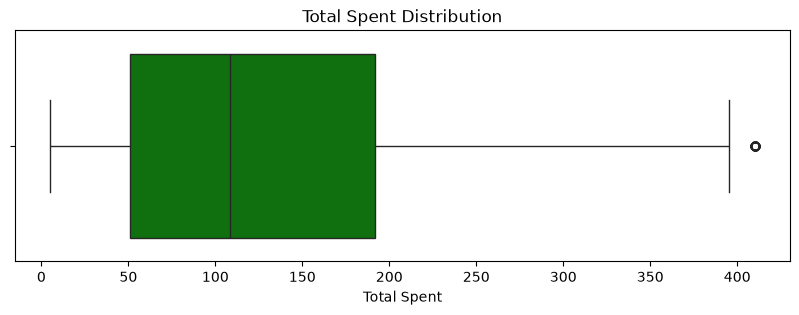

In [ ]:
mp.figure(figsize=(10,3))
mp.title('Total Spent Distribution')
sb.boxplot(x = 'Total Spent', data = df, color = 'green')
mp.show()

### Total Spent Distribution

As mentioned earlier this box plot highlights that anything above the purchase of over **$403.5** is going to be treated as a outlier, the long whiskers going all the way to the right shows that the curve is positively skewed, and customers tend to peak their total spending's at the store at around **$108.5**.

In [ ]:
high_spending_customers = df[df['Total Spent'] > 403.5]

high_spending_customers[['Transaction ID', 'Customer ID', 'Category', 'Quantity', 'Total Spent']].sort_values('Total Spent', ascending = False)
most_valued_customer = high_spending_customers['Customer ID'].value_counts()
highly_spent_category = high_spending_customers['Category'].value_counts()

print(most_valued_customer)
print(highly_spent_category)

Customer ID
CUST_16    6
CUST_12    5
CUST_14    4
CUST_25    3
CUST_17    3
CUST_01    3
CUST_21    3
CUST_08    3
CUST_03    3
CUST_24    3
CUST_02    3
CUST_04    3
CUST_06    2
CUST_22    2
CUST_23    2
CUST_11    2
CUST_13    2
CUST_05    1
CUST_10    1
CUST_09    1
CUST_19    1
CUST_20    1
CUST_15    1
CUST_07    1
CUST_18    1
Name: count, dtype: int64
Category
Food                                  12
Beverages                             11
Butchers                              11
Electric household essentials         10
Furniture                              8
Milk Products                          3
Computers and electric accessories     3
Patisserie                             2
Name: count, dtype: int64


### Highly Valued Customers and Category

Cust_16 tends to the be the customer to the make the most purchase, where the total spent is higher than the upper boundary fence, bringing his 6 purchases in the outlier zone, meaning Cust_16 is one of the reasons why the 'Total Spent Distribution' was skewed, making Cust_16 a highly valued customer.
On the other hand, the category of Food seems to dominate where people tend to spend a lot more compared to other categories.


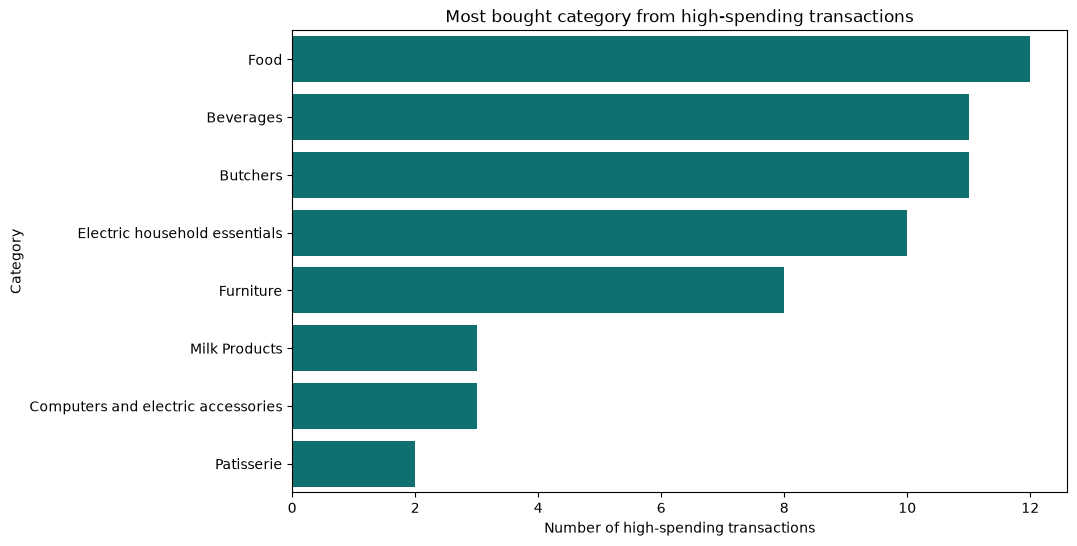

In [ ]:
mp.figure(figsize=(10,6))
mp.title('Most bought category from high-spending transactions')
mp.xlabel('Number of high-spending transactions')
sb.countplot(data = high_spending_customers, y = 'Category', order = high_spending_customers['Category'].value_counts().index, color = 'teal')
mp.show()

### Most bought category by high spending customers

As per the visuals shown above, the highest paying customers tend to spend more money on Food Categories relative to the other categories.

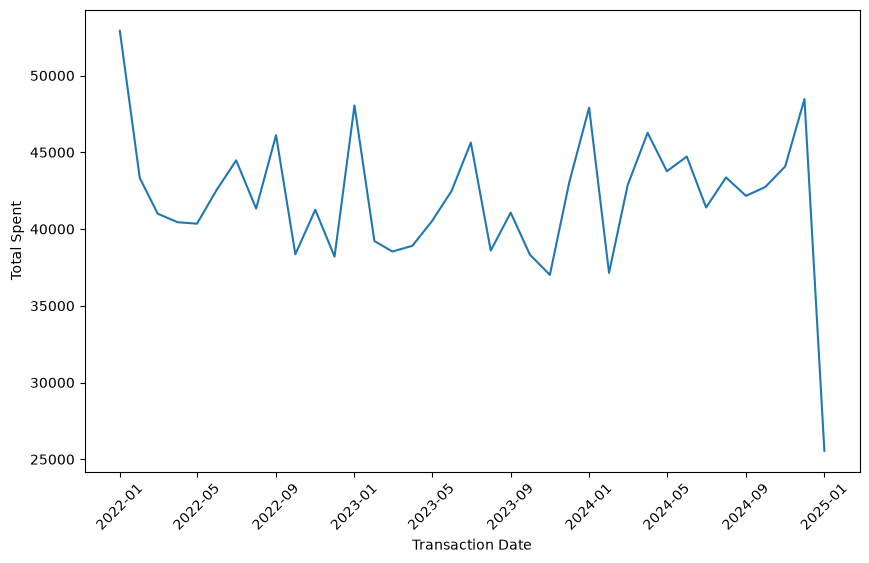

In [ ]:
monthly_sales = (
    df.groupby(df['Transaction Date'].dt.to_period('M'))['Total Spent'].sum().reset_index()
)
monthly_sales['Transaction Date'] = monthly_sales['Transaction Date'].dt.to_timestamp()

mp.figure(figsize=(10,6))
sb.lineplot(x = 'Transaction Date', y = 'Total Spent', data=monthly_sales)
mp.xticks(rotation = 45)
mp.show()

### Monthly Sales Trend

The line chart shows that the total monthly sales tend to fluctuate over time rather than increasing constantly. The decrease in January 2025 should be interpreted carefully because the dataset only includes a partial month of transactions, making January not suitable for comparison with other months.

1186.0
66276.0
1.7894863902468465


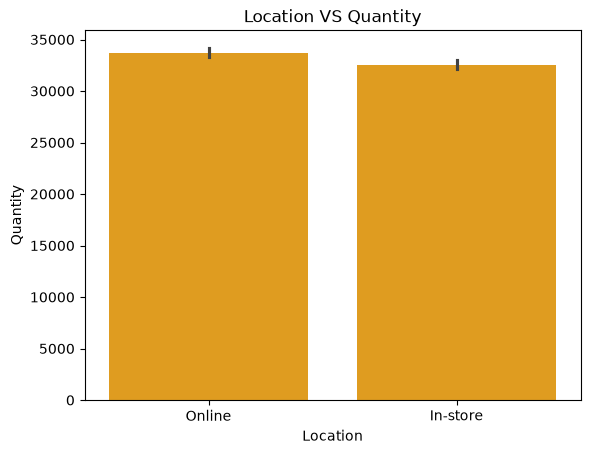

In [22]:
difference = (df.loc[df['Location'] == 'Online', 'Quantity'].sum()) - (df.loc[df['Location'] == 'In-store', 'Quantity'].sum())
total = (df.loc[df['Location'] == 'Online', 'Quantity'].sum()) + (df.loc[df['Location'] == 'In-store', 'Quantity'].sum())
print(difference)
print(total)

percent = (difference/total)*100
print(percent)

mp.figure(figsize=(8, 5))
mp.title('Quantity Purchased by Location')
sb.barplot(x = 'Location', y = 'Quantity', data = df, estimator = 'sum', color = 'orange')
mp.ylabel('Total Quantity Purchased')
mp.savefig('visualizations/location_quantity_purchases.png', dpi=150, bbox_inches='tight')
mp.show()

### Location VS Quantity

Online purchases accounted for **1.79%** more of the combined quantity than In-store purchases.

In [29]:
from scipy.stats import ttest_ind

online_qty = df.loc[df['Location'] == 'Online', 'Quantity']
instore_qty = df.loc[df['Location'] == 'In-store', 'Quantity']

t_stat, p_value = ttest_ind(online_qty, instore_qty, equal_var = False)

print(f'Online mean: {online_qty.mean():.2f}')
print(f"In-store mean: {instore_qty.mean():.2f}")
print(f'T-stat : {t_stat:.3f}')
print(f'p-value: {p_value:.3f}')


Online mean: 5.56
In-store mean: 5.51
T-stat : 0.871
p-value: 0.384


### Statistical Significance of the mean quantity purchases based on location

There was no statistical significance difference between the mean quantity purchased per transaction between online and in-store purchases, since the p = 0.384, meaning p>0.05.